<a href="https://colab.research.google.com/github/Xyrfo/Pembelajaran-Mesin/blob/main/JS07/tugas_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Lab JS07 - Klasterisasi Data Nasabah Kartu Kredit

1. Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu `Avg_Credit_Limit` dan `Total_credit_card`. Apakah sebaran data dapat dikatakan linier?
2. Buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah $k$ yang terbaik dengan menggunakan ***elbow method***. Lengkapi analisis Anda dengan *linechart* dan hasil analisis mengapa Anda memilih nilai tersebut.
3. Gambarkan hasil klasterisasi dengan model K-Means dengan menggunakan scatterplot.
4. Buatlah model klasterisasi dengan menggunakan DBSCAN **dengan seluruh variabel yang dapat digunakan**.
5. Tentukan jumlah $k$ yang terbaik dengan menggunakan ***elbow method***. Lengkapi analisis Anda dengan *linechart* dan hasil analisis mengapa Anda memilih nilai tersebut.
6. Tentukan nilai *silhouette score* dan DBI dari model DBSCAN.

> **Catatan:** DBSCAN tidak memerlukan jumlah klaster $k$, sehingga *elbow method* tidak berlaku langsung untuk DBSCAN. Pada notebook ini, poin 5 dikerjakan dengan dua pendekatan: (a) *elbow method* K-Means pada seluruh fitur, dan (b) *knee plot* jarak k-tetangga untuk memilih `eps` DBSCAN. Konfirmasikan ke dosen pengampu bila ada ketentuan khusus.

## Langkah 0 - Import Library dan Upload Dataset

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

uploaded = files.upload()
nama_file = next(iter(uploaded))
df = pd.read_csv(nama_file)
print('Ukuran data:', df.shape)
df.head()

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset (1).csv
Ukuran data: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


## Inspeksi Data

In [6]:
df.info()
print()
print(df.describe())
print()
print('Nilai kosong per kolom:')
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

            Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
count  660.000000    660.000000        660.000000          660.000000   
mean   330.500000  55141.443939      34574.242424            4.706061   
std    190.669872  25627.772200      37625.487804            2.167835   
min      1.000000  11265.000000       3000.000000            1.000000   
25%    165.750000  33825.250000      10000.000000          

## Poin 1 - Scatterplot `Avg_Credit_Limit` vs `Total_credit_card`

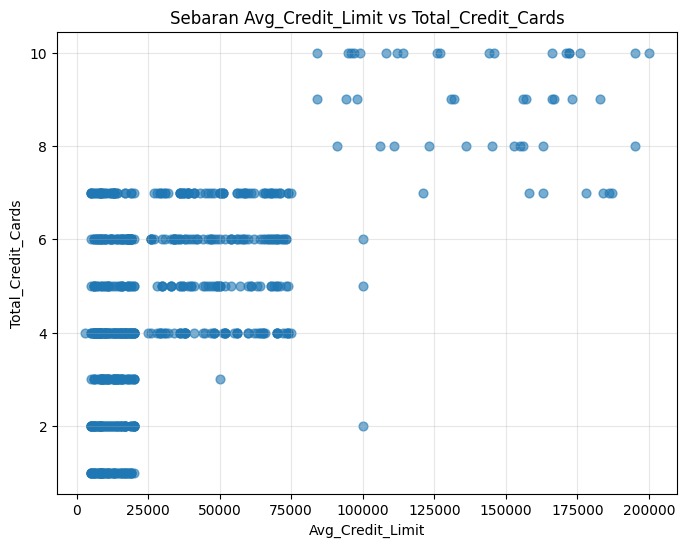

Koefisien korelasi Pearson: 0.6089


In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], s=40, alpha=0.6)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Sebaran Avg_Credit_Limit vs Total_Credit_Cards')
plt.grid(alpha=0.3)
plt.show()

korelasi = df['Avg_Credit_Limit'].corr(df['Total_Credit_Cards'])
print(f'Koefisien korelasi Pearson: {korelasi:.4f}')

**Analisis:** Amati scatterplot dan nilai korelasi. Jika titik-titik cenderung mengikuti satu arah garis lurus dengan korelasi mendekati +1 atau -1, sebaran dapat dikatakan linier. Jika titik menyebar membentuk kelompok atau pola tidak lurus, sebaran bersifat non-linier. Pada dataset ini, sebaran umumnya membentuk beberapa kelompok terpisah sehingga **tidak sepenuhnya linier**, dan klasterisasi lebih tepat digunakan daripada regresi linier.

## Poin 2 - K-Means dan Elbow Method

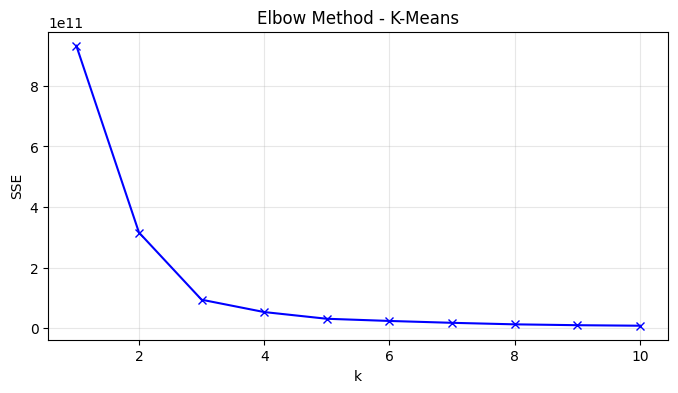

k=1: SSE=932931365218.19
k=2: SSE=315872383980.64
k=3: SSE=93831368689.85
k=4: SSE=53044221929.51
k=5: SSE=30884746200.31
k=6: SSE=23676885595.56
k=7: SSE=17506496809.03
k=8: SSE=12485880524.74
k=9: SSE=9648842671.05
k=10: SSE=7910237785.84


In [11]:
# Gunakan dua variabel pada poin 1
X2 = df[['Avg_Credit_Limit', 'Total_Credit_Cards']].dropna()

sse = []
K = range(1, 11)
for k in K:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X2)
    sse.append(model.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(list(K), sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Elbow Method - K-Means')
plt.grid(alpha=0.3)
plt.show()

for k, nilai in zip(K, sse):
    print(f'k={k}: SSE={nilai:.2f}')

In [9]:
# Deteksi titik elbow sederhana: penurunan terbesar relatif terhadap penurunan berikutnya
penurunan = [sse[i] - sse[i+1] for i in range(len(sse)-1)]
kandidat = int(np.argmax(penurunan)) + 1
print(f'Kandidat k terbaik berdasarkan penurunan SSE terbesar: {kandidat}')
print('Pilih k pada posisi siku, yaitu penurunan tajam yang diikuti penurunan stabil.')

Kandidat k terbaik berdasarkan penurunan SSE terbesar: 1
Pilih k pada posisi siku, yaitu penurunan tajam yang diikuti penurunan stabil.


**Analisis:** Jumlah klaster terbaik **bukan** nilai dengan SSE terkecil, karena SSE selalu menurun saat $k$ bertambah. Pilih $k$ pada posisi "siku", yaitu titik ketika penurunan SSE masih tajam lalu melandai. Berdasarkan grafik di atas, nilai $k$ pada posisi tersebut adalah kandidat terbaik.

## Poin 3 - Scatterplot Hasil Klasterisasi K-Means

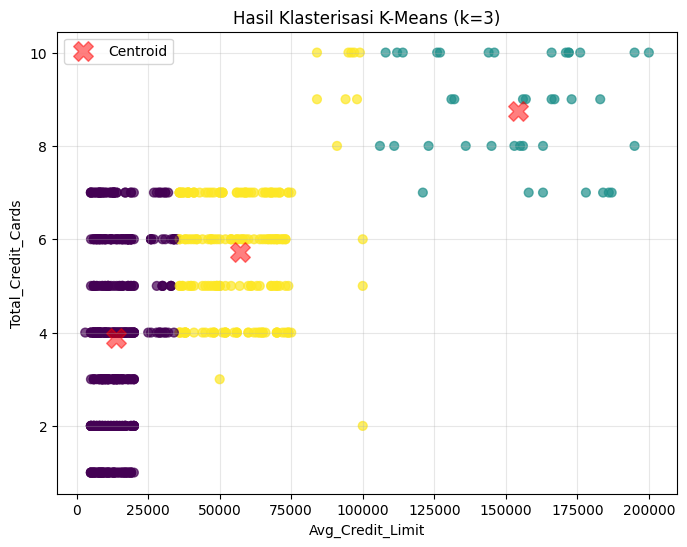

SSE model: 93831368689.85
Silhouette Score: 0.7187


In [12]:
# Tentukan k_terbaik berdasarkan pengamatan elbow chart secara manual (misalnya k=3)
k_terbaik = 3 if kandidat == 1 else kandidat
kmeans = KMeans(n_clusters=k_terbaik, random_state=42, n_init=10)
label_kmeans = kmeans.fit_predict(X2)

plt.figure(figsize=(8, 6))
plt.scatter(X2.iloc[:, 0], X2.iloc[:, 1], c=label_kmeans, s=40, cmap='viridis', alpha=0.7)
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5, marker='X', label='Centroid')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title(f'Hasil Klasterisasi K-Means (k={k_terbaik})')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f'SSE model: {kmeans.inertia_:.2f}')
print(f'Silhouette Score: {silhouette_score(X2, label_kmeans):.4f}')

## Poin 4 - DBSCAN dengan Seluruh Variabel

Seluruh kolom numerik digunakan sebagai fitur. Standardisasi (`StandardScaler`) diperlukan karena `eps` DBSCAN berbasis jarak, sedangkan skala antarfitur berbeda jauh.

In [13]:
X_all = df.select_dtypes(include=np.number).dropna()
print('Fitur yang digunakan:', X_all.columns.tolist())
print('Jumlah fitur:', X_all.shape[1])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)
print('Shape setelah standardisasi:', X_scaled.shape)

Fitur yang digunakan: ['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
Jumlah fitur: 7
Shape setelah standardisasi: (660, 7)


### Poin 5 - Elbow Method (K-Means) dan Knee Plot (DBSCAN)

Bagian pertama: *elbow method* K-Means pada seluruh fitur.

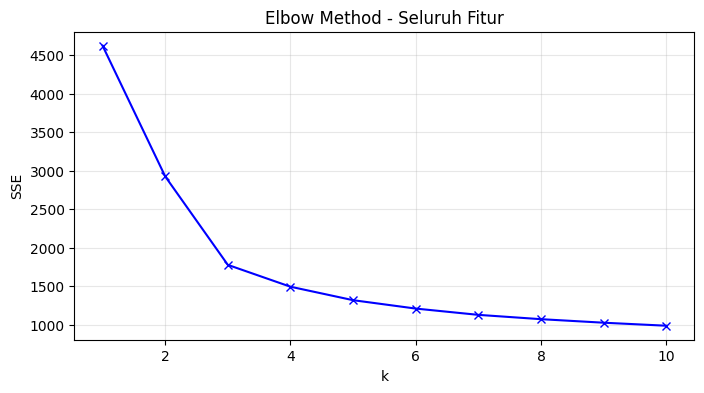

Kandidat k terbaik (seluruh fitur): 1


In [14]:
sse_all = []
K_all = range(1, 11)
for k in K_all:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    sse_all.append(model.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(list(K_all), sse_all, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Elbow Method - Seluruh Fitur')
plt.grid(alpha=0.3)
plt.show()

penurunan_all = [sse_all[i] - sse_all[i+1] for i in range(len(sse_all)-1)]
k_all = int(np.argmax(penurunan_all)) + 1
print(f'Kandidat k terbaik (seluruh fitur): {k_all}')

Bagian kedua: *knee plot* jarak k-tetangga untuk memilih `eps` DBSCAN. Jarak ke tetangga ke-`min_samples` diurutkan, lalu dicari titik "knee" (lengkung tajam) sebagai nilai `eps`.

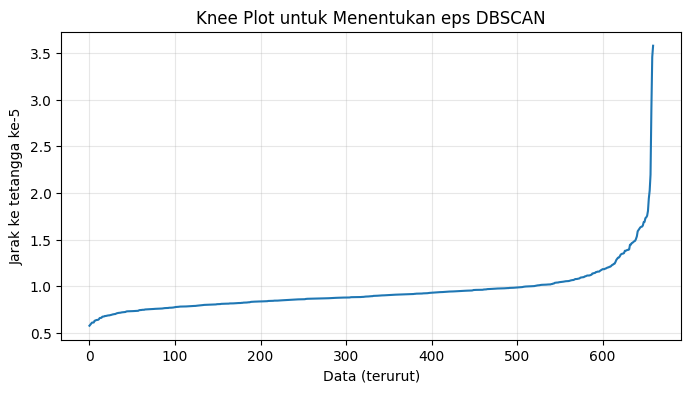

Nilai jarak minimum : 0.5753
Nilai jarak median  : 0.8922
Nilai jarak maksimum: 3.5789
Gunakan nilai pada titik knee sebagai eps.


In [15]:
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, _ = neighbors_fit.kneighbors(X_scaled)
jarak = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(jarak)
plt.xlabel('Data (terurut)')
plt.ylabel(f'Jarak ke tetangga ke-{min_samples}')
plt.title('Knee Plot untuk Menentukan eps DBSCAN')
plt.grid(alpha=0.3)
plt.show()

print('Nilai jarak minimum :', round(jarak.min(), 4))
print('Nilai jarak median  :', round(np.median(jarak), 4))
print('Nilai jarak maksimum:', round(jarak.max(), 4))
print('Gunakan nilai pada titik knee sebagai eps.')

### Model DBSCAN

In [16]:
eps_pilihan = float(np.median(jarak))
print(f'eps yang digunakan (median jarak): {eps_pilihan:.4f}')

dbscan = DBSCAN(eps=eps_pilihan, min_samples=min_samples)
label_db = dbscan.fit_predict(X_scaled)

n_cluster = len(set(label_db)) - (1 if -1 in label_db else 0)
n_noise = int((label_db == -1).sum())

print(f'Jumlah cluster terbentuk: {n_cluster}')
print(f'Jumlah noise: {n_noise} dari {len(label_db)} data ({n_noise/len(label_db)*100:.2f}%)')

eps yang digunakan (median jarak): 0.8922
Jumlah cluster terbentuk: 9
Jumlah noise: 136 dari 660 data (20.61%)


## Poin 6 - Silhouette Score dan DBI dari DBSCAN

Metrik dihitung pada data yang **bukan noise**, karena label `-1` bukan klaster.

In [17]:
mask = label_db != -1

if len(set(label_db[mask])) > 1:
    sil = silhouette_score(X_scaled[mask], label_db[mask])
    dbi = davies_bouldin_score(X_scaled[mask], label_db[mask])
    print(f'Silhouette Score DBSCAN: {sil:.4f}')
    print(f'Davies-Bouldin Index DBSCAN: {dbi:.4f}')
    print()
    print('Interpretasi:')
    print('- Silhouette mendekati +1 berarti klaster rapat dan terpisah baik.')
    print('- DBI semakin kecil semakin baik.')
else:
    print('Klaster valid kurang dari 2. Sesuaikan eps atau min_samples.')
    print(f'Jumlah label unik: {set(label_db)}')

Silhouette Score DBSCAN: -0.0392
Davies-Bouldin Index DBSCAN: 1.3589

Interpretasi:
- Silhouette mendekati +1 berarti klaster rapat dan terpisah baik.
- DBI semakin kecil semakin baik.


## Kesimpulan

1. Sebaran `Avg_Credit_Limit` vs `Total_credit_card` membentuk beberapa kelompok sehingga tidak sepenuhnya linier.
2. K-Means memerlukan `k` yang ditentukan melalui *elbow method*, dan hasilnya divisualisasikan pada scatterplot beserta centroid.
3. DBSCAN dijalankan pada seluruh fitur numerik yang telah distandardisasi, dengan `eps` dari *knee plot* dan `min_samples` yang ditentukan.
4. Performa DBSCAN dinilai dengan *silhouette score* dan DBI pada data non-noise, serta persentase noise.